In [1]:
import sys

sys.path.append("../src")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression, LogisticRegression, Ridge
from sklearn.metrics import accuracy_score, r2_score
from sklearn.preprocessing import StandardScaler
from utils import fix_seed, gerar_dados_sinteticos_queimadas

fix_seed(42)

# Carregamento dos dados
df = gerar_dados_sinteticos_queimadas(n_samples=1000)

features = [
    "dias_sem_chuva",
    "precipitacao",
    "temperatura_max",
    "umidade_relativa",
    "velocidade_vento",
]
X_raw = df[features].values
y_cont = df["risco_fogo"].values  # Alvo contínuo para Regressão Linear
y_class = df["risco_critico"].values  # Alvo binário para Regressão Logística

# Padronização dos atributos (essencial para convergência do Gradiente Descendente)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_raw)

print(
    f"Dados preparados: {X_scaled.shape[0]} amostras."
)
print(f"Intervalo do Risco de Fogo contínuo: [{y_cont.min():.2f}, {y_cont.max():.2f}]")

Dados preparados: 1000 amostras.
Intervalo do Risco de Fogo contínuo: [0.00, 0.84]


In [2]:
# Usando apenas 'dias_sem_chuva' (índice 0)
x_uni = df["dias_sem_chuva"].values

# Fórmula fechada MNO: w1 = Cov(x,y) / Var(x)
x_mean, y_mean = np.mean(x_uni), np.mean(y_cont)
w1 = np.sum((x_uni - x_mean) * (y_cont - y_mean)) / np.sum((x_uni - x_mean) ** 2)
w0 = y_mean - w1 * x_mean

y_pred_uni = w0 + w1 * x_uni
r2_uni = r2_score(y_cont, y_pred_uni)

print("=== REGRESSÃO LINEAR UNIVARIADA (FÓRMULA FECHADA) ===")
print(f"Equação: risco_fogo = {w0:.4f} + ({w1:.4f} * dias_sem_chuva)")
print(f"R² Score: {r2_uni:.4f}")

=== REGRESSÃO LINEAR UNIVARIADA (FÓRMULA FECHADA) ===
Equação: risco_fogo = 0.1121 + (0.0281 * dias_sem_chuva)
R² Score: 0.6380


In [3]:
class LinearRegressionGD:

    def __init__(self, alpha=0.01, num_iter=1000, l2_penalty=0.0):
        self.alpha = alpha
        self.num_iter = num_iter
        self.l2_penalty = l2_penalty
        self.w = None
        self.bias = None
        self.cost_history = []

    def fit(self, X, y):
        n_samples, n_features = X.shape
        self.w = np.zeros(n_features)
        self.bias = 0.0

        for _ in range(self.num_iter):
            y_pred = np.dot(X, self.w) + self.bias
            error = y_pred - y

            # Gradiente com regularização L2 (Ridge)
            grad_w = (
                1 / n_samples
            ) * np.dot(X.T, error) + (self.l2_penalty / n_samples) * self.w
            grad_b = (1 / n_samples) * np.sum(error)

            self.w -= self.alpha * grad_w
            self.bias -= self.alpha * grad_b

            mse = np.mean(error**2)
            self.cost_history.append(mse)

    def predict(self, X):
        return np.dot(X, self.w) + self.bias


# Treinamento do modelo sem regularização
lr_gd = LinearRegressionGD(alpha=0.05, num_iter=1000, l2_penalty=0.0)
lr_gd.fit(X_scaled, y_cont)
y_pred_gd = lr_gd.predict(X_scaled)

print("=== REGRESSÃO LINEAR MULTIVARIADA (GRADIENTE DESCENDENTE DO ZERO) ===")
print(f"R² Score (Gradiente Descendente): {r2_score(y_cont, y_pred_gd):.4f}")

# Comparação com Scikit-Learn
sk_lr = LinearRegression()
sk_lr.fit(X_scaled, y_cont)
print(f"R² Score (Scikit-Learn LinearRegression): {r2_score(y_cont, sk_lr.predict(X_scaled)):.4f}")

=== REGRESSÃO LINEAR MULTIVARIADA (GRADIENTE DESCENDENTE DO ZERO) ===
R² Score (Gradiente Descendente): 0.8242
R² Score (Scikit-Learn LinearRegression): 0.8242


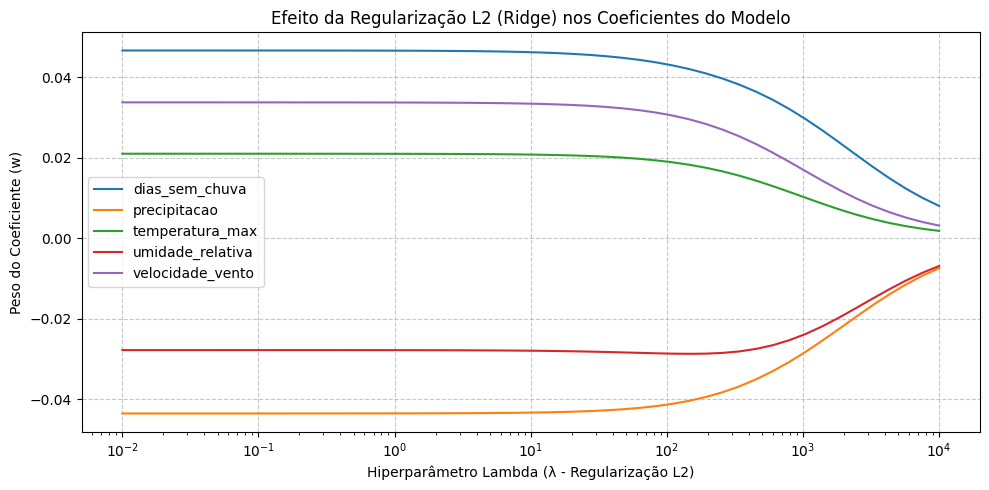

In [4]:
lambdas = np.logspace(-2, 4, 50)
coefs_custom = []
coefs_sklearn = []

for lmbda in lambdas:
    # Do zero
    ridge_gd = LinearRegressionGD(alpha=0.05, num_iter=800, l2_penalty=lmbda)
    ridge_gd.fit(X_scaled, y_cont)
    coefs_custom.append(ridge_gd.w)

    # Scikit-Learn
    sk_ridge = Ridge(alpha=lmbda)
    sk_ridge.fit(X_scaled, y_cont)
    coefs_sklearn.append(sk_ridge.coef_)

coefs_custom = np.array(coefs_custom)

# Plotagem da variação dos coeficientes
plt.figure(figsize=(10, 5))
for i, feat in enumerate(features):
    plt.plot(lambdas, coefs_custom[:, i], label=feat)

plt.xscale("log")
plt.xlabel("Hiperparâmetro Lambda (λ - Regularização L2)")
plt.ylabel("Peso do Coeficiente (w)")
plt.title("Efeito da Regularização L2 (Ridge) nos Coeficientes do Modelo")
plt.grid(True, linestyle="--", alpha=0.7)
plt.legend()
plt.tight_layout()
plt.show()

In [5]:
class LogisticRegressionGD:

    def __init__(self, alpha=0.1, num_iter=1000):
        self.alpha = alpha
        self.num_iter = num_iter
        self.w = None
        self.bias = None

    def _sigmoid(self, z):
        return 1 / (1 + np.exp(-np.clip(z, -25, 25)))

    def fit(self, X, y):
        n_samples, n_features = X.shape
        self.w = np.zeros(n_features)
        self.bias = 0.0

        for _ in range(self.num_iter):
            linear_model = np.dot(X, self.w) + self.bias
            y_predicted = self._sigmoid(linear_model)

            grad_w = (1 / n_samples) * np.dot(X.T, (y_predicted - y))
            grad_b = (1 / n_samples) * np.sum(y_predicted - y)

            self.w -= self.alpha * grad_w
            self.bias -= self.alpha * grad_b

    def predict_proba(self, X):
        return self._sigmoid(np.dot(X, self.w) + self.bias)

    def predict(self, X, threshold=0.5):
        return (self.predict_proba(X) >= threshold).astype(int)


# Treinamento e avaliação da Regressão Logística
log_reg = LogisticRegressionGD(alpha=0.1, num_iter=1000)
log_reg.fit(X_scaled, y_class)
y_pred_log = log_reg.predict(X_scaled)
acc_custom = accuracy_score(y_class, y_pred_log)

# Scikit-Learn Logistic Regression
sk_log_reg = LogisticRegression(random_state=42)
sk_log_reg.fit(X_scaled, y_class)
acc_sklearn = accuracy_score(y_class, sk_log_reg.predict(X_scaled))

print("=== REGRESSÃO LOGÍSTICA (PROBLEMA DE CLASSIFICAÇÃO) ===")
print(f"Acurácia (Implementação do Zero): {acc_custom * 100:.2f}%")
print(f"Acurácia (Scikit-Learn LogisticRegression): {acc_sklearn * 100:.2f}%")

=== REGRESSÃO LOGÍSTICA (PROBLEMA DE CLASSIFICAÇÃO) ===
Acurácia (Implementação do Zero): 99.80%
Acurácia (Scikit-Learn LogisticRegression): 99.80%
